# Predicting household electricity consumption (kW)

In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, roc_curve, roc_auc_score


In [56]:
# Getting the data
df = pd.read_csv('data/household_power_consumption.txt',
                 sep=";",
                 low_memory=False)

## Data Cleaning

In [57]:
print(df.shape)

(2075259, 9)


In [58]:
# Checking the null values 
print(df.isnull().sum())

Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64


In [59]:
# Checking for missing values
for col in df.columns:
    n = (df[col].astype(str) == "?").sum()
    if n > 0:
        print(f"{col}: {n} literal '?' values")

Global_active_power: 25979 literal '?' values
Global_reactive_power: 25979 literal '?' values
Voltage: 25979 literal '?' values
Global_intensity: 25979 literal '?' values
Sub_metering_1: 25979 literal '?' values
Sub_metering_2: 25979 literal '?' values


### Important Note:
We can notice that for the Sub_metering_3 column we don't have any "?" and after checking the raw data for the rows that have "?" across all columns, we noticed that we have 8 values and not 9 (e.g 13/1/2010;12:50:00;?;?;?;?;?;?;).\
So we decided to reload the data line by line and fix this issue by replacing the "?" with NaN and adding NaN also for the missing values of Sub_metering_3.

In [60]:
cols = ["Date","Time","Global_active_power","Global_reactive_power","Voltage",
        "Global_intensity","Sub_metering_1","Sub_metering_2","Sub_metering_3"]

rows = []
with open("data/household_power_consumption.txt", "r") as f:
    header = f.readline()                      # skip the header line
    for line in f:
        parts = line.rstrip("\n").split(";")
        # pad to 9 fields: a trailing ';' means the last field is absent
        while len(parts) < len(cols):
            parts.append(np.nan)
        # any literal '?' becomes a real missing value
        parts = [np.nan if p in ("?", "") else p for p in parts]
        rows.append(parts)

df = pd.DataFrame(rows, columns=cols)

In [61]:
# verification
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())

(2075259, 9)
Date                     object
Time                     object
Global_active_power      object
Global_reactive_power    object
Voltage                  object
Global_intensity         object
Sub_metering_1           object
Sub_metering_2           object
Sub_metering_3           object
dtype: object
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [62]:
# Convert the columns to numeric
num_cols = [
    "Global_active_power","Global_reactive_power","Voltage",
    "Global_intensity","Sub_metering_1","Sub_metering_2","Sub_metering_3"
]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

In [63]:
# check if the 25979 nulls are all in the same rows
print("Rows where all 7 '?' columns are null:",
      df[["Global_active_power","Global_reactive_power","Voltage",
        "Global_intensity","Sub_metering_1","Sub_metering_2","Sub_metering_3"]].isnull().all(axis=1).sum())

Rows where all 7 '?' columns are null: 25979


In [64]:
# Drop those null rows
df = df.dropna(subset=num_cols)

In [ ]:
# Combine the 'date' and 'time' in one column
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"],
                                format="%d/%m/%Y %H:%M:%S")
df = df.drop(columns=["Date","Time"])

In [72]:
# Verification
print(df.shape)
print(df.dtypes)

(2049280, 8)
datetime                 datetime64[ns]
Global_active_power             float64
Global_reactive_power           float64
Voltage                         float64
Global_intensity                float64
Sub_metering_1                  float64
Sub_metering_2                  float64
Sub_metering_3                  float64
dtype: object


In [73]:
# Check for duplicate timestamps and full duplicate rows
print("Duplicate datetimes:", df["datetime"].duplicated().sum())
print("Duplicate full rows:", df.duplicated().sum())

Duplicate datetimes: 0
Duplicate full rows: 0


In [74]:
num_cols = ["Global_active_power","Global_reactive_power","Voltage",
            "Global_intensity","Sub_metering_1","Sub_metering_2","Sub_metering_3"]

for c in num_cols:
    n = (df[c] == 0).sum()
    print(f"{c}: {n} zeros ({n/len(df)*100:.2f}%)")

Global_active_power: 0 zeros (0.00%)
Global_reactive_power: 481561 zeros (23.50%)
Voltage: 0 zeros (0.00%)
Global_intensity: 0 zeros (0.00%)
Sub_metering_1: 1880175 zeros (91.75%)
Sub_metering_2: 1436830 zeros (70.11%)
Sub_metering_3: 852092 zeros (41.58%)


In [ ]:
# Convert the clean dataset to csv
df.to_csv("household_clean.csv", index=False) 

## Pre-treatment of data

In [2]:
df = pd.read_csv('household_clean.csv')
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

In [10]:
# EDA
print(df.shape)
print(df.dtypes)
print(df.describe())

(2049280, 8)
datetime                 datetime64[ns]
Global_active_power             float64
Global_reactive_power           float64
Voltage                         float64
Global_intensity                float64
Sub_metering_1                  float64
Sub_metering_2                  float64
Sub_metering_3                  float64
dtype: object
                            datetime  Global_active_power  \
count                        2049280         2.049280e+06   
mean   2008-12-02 00:59:44.397740544         1.091615e+00   
min              2006-12-16 17:24:00         7.600000e-02   
25%              2007-12-10 05:37:45         3.080000e-01   
50%              2008-11-30 01:22:30         6.020000e-01   
75%              2009-11-23 20:31:15         1.528000e+00   
max              2010-11-26 21:02:00         1.112200e+01   
std                              NaN         1.057294e+00   

       Global_reactive_power       Voltage  Global_intensity  Sub_metering_1  \
count           2.04928

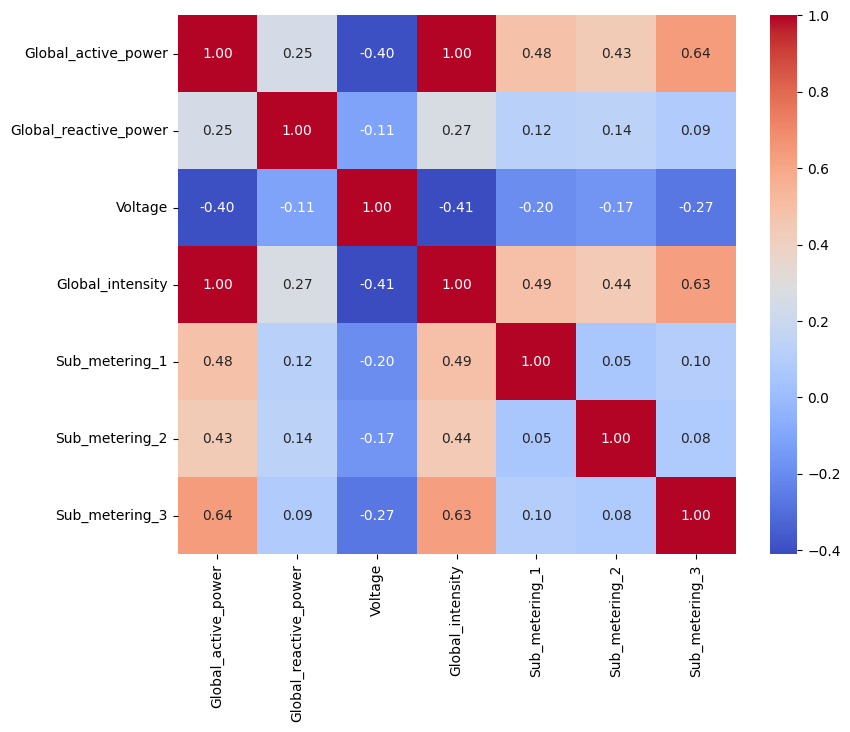

In [11]:
# Correlation Heatmap
num_cols = ["Global_active_power","Global_reactive_power","Voltage",
            "Global_intensity","Sub_metering_1","Sub_metering_2","Sub_metering_3"]

corr = df[num_cols].corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2676\3137861808.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hourly_avg.index, y=hourly_avg.values, palette="viridis")


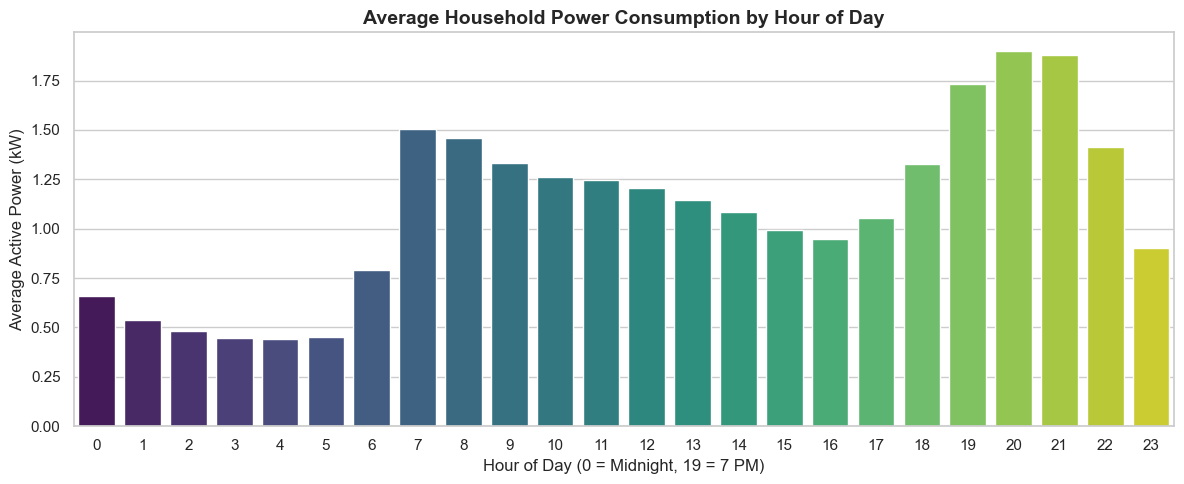

In [4]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))

# Create the bar chart
# We group by 'hour' and take the mean of the target variable
hourly_avg = df.groupby(df["datetime"].dt.hour)["Global_active_power"].mean()

sns.barplot(x=hourly_avg.index, y=hourly_avg.values, palette="viridis")

plt.title("Average Household Power Consumption by Hour of Day", fontsize=14, fontweight='bold')
plt.xlabel("Hour of Day (0 = Midnight, 19 = 7 PM)", fontsize=12)
plt.ylabel("Average Active Power (kW)", fontsize=12)
plt.xticks(range(0, 24))

plt.tight_layout()
plt.savefig("hourly_consumption.png", dpi=120, bbox_inches="tight")
plt.show()

In [46]:
# Work on the features

# Create new exact date and time columns to get more accurate prediction
df["hour"]        = df["datetime"].dt.hour
df["day_of_week"] = df["datetime"].dt.dayofweek
df["month"]       = df["datetime"].dt.month
print(df[["datetime","hour","day_of_week","month"]].head())

# Add some lag_features
df["lag_1hour"] = df["Global_active_power"].shift(60)
df["lag_1day"]  = df["Global_active_power"].shift(1440)


             datetime  hour  day_of_week  month
0 2006-12-17 17:24:00    17            6     12
1 2006-12-17 17:25:00    17            6     12
2 2006-12-17 17:26:00    17            6     12
3 2006-12-17 17:27:00    17            6     12
4 2006-12-17 17:28:00    17            6     12


In [47]:
# Drop rows with NaN created by the lags

before = len(df)
df = df.dropna(subset=["lag_1hour","lag_1day"]).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows; {len(df)} remain")

Dropped 1440 rows; 2046400 remain


> ### We'll compare 5 regression models using different features for each

## *Model A* 

In [50]:
# Splitting the data and training the model
FEATURES_A = ["hour","day_of_week","month"]
TARGET_A   = "Global_active_power"

X_A = pd.get_dummies(df[FEATURES_A], columns=["hour", "day_of_week", "month"], drop_first=True)
y_A = df[TARGET_A]

split_idx = int(len(X_A) * 0.8)

XA_train, XA_test = X_A.iloc[:split_idx], X_A.iloc[split_idx:]
yA_train, yA_test = y_A.iloc[:split_idx], y_A.iloc[split_idx:]

model_A = LinearRegression()
model_A.fit(XA_train, yA_train)

yA_pred = model_A.predict(XA_test)


In [51]:
# Metrics of model A
mae  = mean_absolute_error(yA_test, yA_pred)
rmse = np.sqrt(mean_squared_error(yA_test, yA_pred))
r2   = r2_score(yA_test, yA_pred)

results = pd.DataFrame({
    "Model": ["A: time only"],
    "MAE":  [round(mae, 4)],
    "RMSE": [round(rmse, 4)],
    "R²":   [round(r2, 4)]
})
print(results)

          Model     MAE    RMSE      R²
0  A: time only  0.5887  0.8098  0.1833


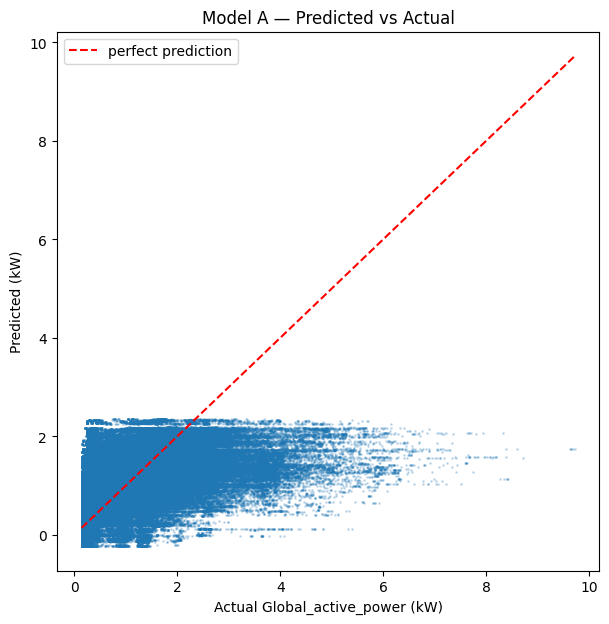

In [23]:
plt.figure(figsize=(7,7))
plt.scatter(yA_test, yA_pred, s=1, alpha=0.2)
plt.plot([yA_test.min(), yA_test.max()],
         [yA_test.min(), yA_test.max()], 'r--', label="perfect prediction")
plt.xlabel("Actual Global_active_power (kW)")
plt.ylabel("Predicted (kW)")
plt.title("Model A — Predicted vs Actual")
plt.legend()
plt.show()

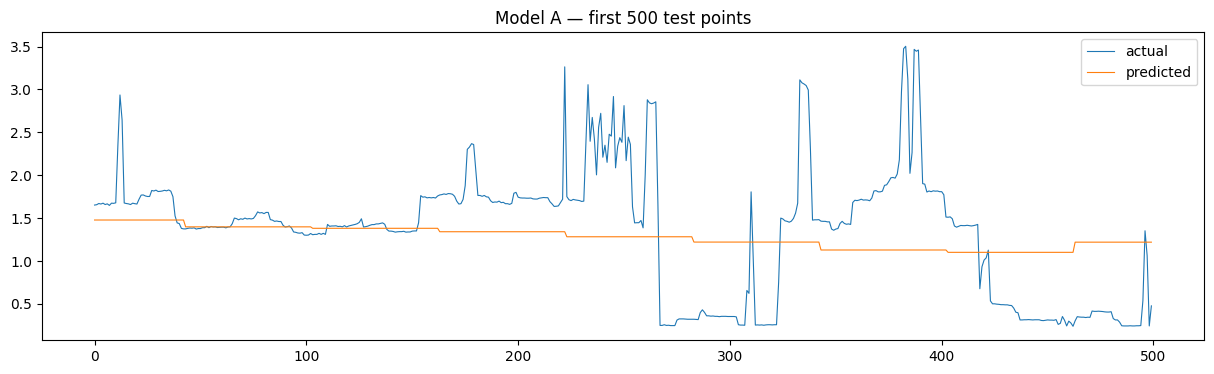

In [24]:
n = 500
plt.figure(figsize=(15,4))
plt.plot(yA_test.values[:n], label="actual", linewidth=0.8)
plt.plot(yA_pred[:n], label="predicted", linewidth=0.8)
plt.legend() 
plt.title("Model A — first 500 test points")
plt.show()

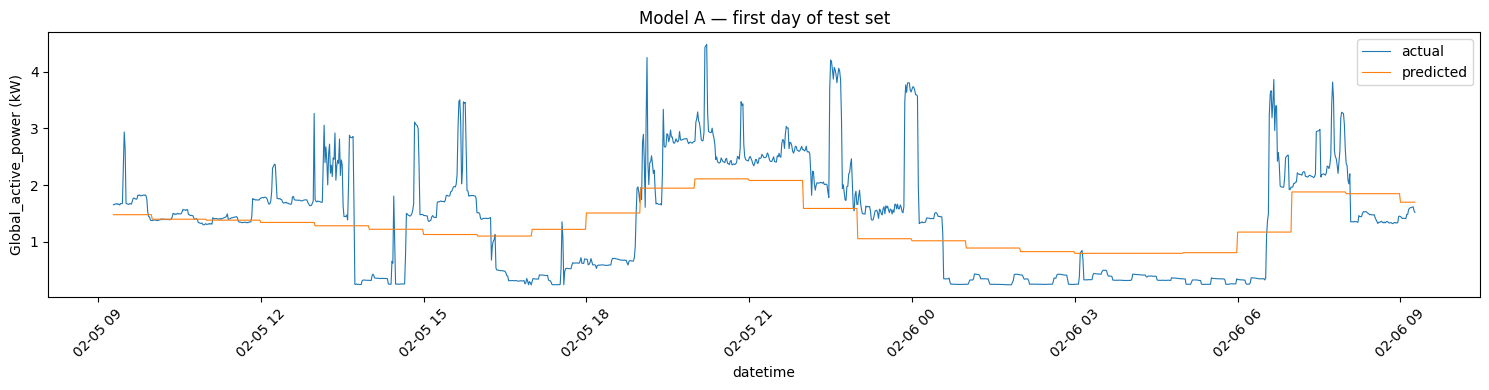

In [25]:
test_datetime = df["datetime"].iloc[split_idx:].reset_index(drop=True)

n = 1440   # one day at minute resolution

plt.figure(figsize=(15,4))
plt.plot(test_datetime[:n], yA_test.values[:n], label="actual", linewidth=0.8)
plt.plot(test_datetime[:n], yA_pred[:n], label="predicted", linewidth=0.8)
plt.xlabel("datetime")
plt.ylabel("Global_active_power (kW)")
plt.title("Model A — first day of test set")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## *Model B*

In [52]:
FEATURES_B = ["hour", "day_of_week", "month", "lag_1hour", "lag_1day"]

X_B = pd.get_dummies(df[FEATURES_B], columns=["hour", "day_of_week", "month"], drop_first=True)
y_B = df["Global_active_power"]

# Same split
XB_train, XB_test = X_B.iloc[:split_idx], X_B.iloc[split_idx:]
yB_train, yB_test = y_B.iloc[:split_idx], y_B.iloc[split_idx:]

model_B = LinearRegression()
model_B.fit(XB_train, yB_train)
yB_pred = model_B.predict(XB_test)

In [53]:
# Metrics of model B
mae_B  = mean_absolute_error(yB_test, yB_pred)
rmse_B = np.sqrt(mean_squared_error(yB_test, yB_pred))
r2_B   = r2_score(yB_test, yB_pred)

# Add to the results table
results = pd.concat([results, pd.DataFrame({
    "Model": ["B: time + lags"],
    "MAE":  [round(mae_B, 4)],
    "RMSE": [round(rmse_B, 4)],
    "R²":   [round(r2_B, 4)]
})], ignore_index=True)

print(results)

            Model     MAE    RMSE      R²
0    A: time only  0.5887  0.8098  0.1833
1  B: time + lags  0.5261  0.7566  0.2871


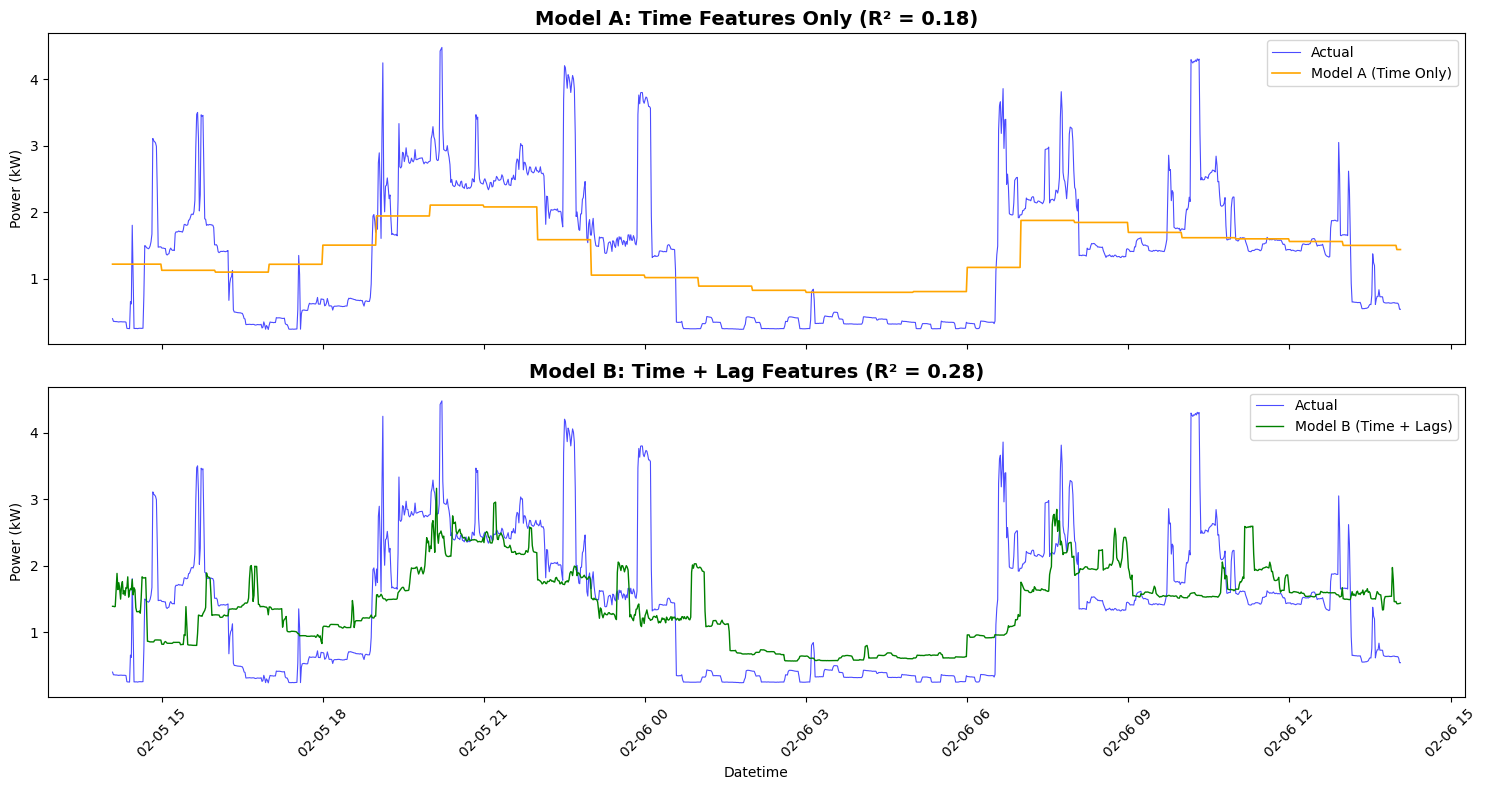

In [55]:
# Get the datetime for the test set
test_datetime = df["datetime"].iloc[split_idx:].reset_index(drop=True)
n = 1440  # One full day

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Top Plot: Model A
axes[0].plot(test_datetime[:n], yA_test.values[:n], label="Actual", color="blue", linewidth=0.8, alpha=0.7)
axes[0].plot(test_datetime[:n], yA_pred[:n], label="Model A (Time Only)", color="orange", linewidth=1.2)
axes[0].set_title("Model A: Time Features Only (R² = 0.18)", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Power (kW)")
axes[0].legend(loc="upper right")

# Bottom Plot: Model B
axes[1].plot(test_datetime[:n], yB_test.values[:n], label="Actual", color="blue", linewidth=0.8, alpha=0.7)
axes[1].plot(test_datetime[:n], yB_pred[:n], label="Model B (Time + Lags)", color="green", linewidth=1.0)
axes[1].set_title("Model B: Time + Lag Features (R² = 0.28)", fontsize=14, fontweight='bold')
axes[1].set_ylabel("Power (kW)")
axes[1].legend(loc="upper right")

plt.xlabel("Datetime")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## *Model C*

In [56]:
# Add the two physical features to the list
FEATURES_C = ["hour", "day_of_week", "month", "lag_1hour", "lag_1day", "Voltage", "Global_reactive_power"]

X_C = pd.get_dummies(df[FEATURES_C], columns=["hour", "day_of_week", "month"], drop_first=True)
XC_train, XC_test = X_C.iloc[:split_idx], X_C.iloc[split_idx:]

model_C = LinearRegression()
model_C.fit(XC_train, yB_train) # y is the same for all models
yC_pred = model_C.predict(XC_test)

mae_C = mean_absolute_error(yB_test, yC_pred)
r2_C = r2_score(yB_test, yC_pred)

## *Model D*

In [57]:
# Add sub-meterings
FEATURES_D = FEATURES_C + ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

X_D = pd.get_dummies(df[FEATURES_D], columns=["hour", "day_of_week", "month"], drop_first=True)
XD_train, XD_test = X_D.iloc[:split_idx], X_D.iloc[split_idx:]

model_D = LinearRegression()
model_D.fit(XD_train, yB_train)
y_pred_D = model_D.predict(XD_test)

mae_D = mean_absolute_error(yB_test, y_pred_D)
r2_D = r2_score(yB_test, y_pred_D)

In [58]:
results = pd.concat([results, pd.DataFrame({
    "Model": ["C: time + lags + voltage", "D: everything (sub-meterings)"],
    "MAE": [round(mae_C, 4), round(mae_D, 4)],
    "RMSE": [np.sqrt(mean_squared_error(yB_test, yC_pred)), np.sqrt(mean_squared_error(yB_test, y_pred_D))],
    "R²": [round(r2_C, 4), round(r2_D, 4)]
})], ignore_index=True)
print(results)

                           Model     MAE      RMSE      R²
0                   A: time only  0.5887  0.809800  0.1833
1                 B: time + lags  0.5261  0.756600  0.2871
2       C: time + lags + voltage  0.4942  0.697550  0.3941
3  D: everything (sub-meterings)  0.2447  0.344135  0.8525


## *Model E*

In [59]:
# Features: No time, no lags. Just the physical measurements.
FEATURES_E = ["Voltage", "Global_reactive_power", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

X_E = df[FEATURES_E].copy()
y_E = df["Global_active_power"].copy()

# Same chronological split
XE_train, XE_test = X_E.iloc[:split_idx], X_E.iloc[split_idx:]

# Train
model_E = LinearRegression()
model_E.fit(XE_train, yB_train) # yB_train is the same as y_E train
y_pred_E = model_E.predict(XE_test)

# Metrics
mae_E = mean_absolute_error(yB_test, y_pred_E)
r2_E = r2_score(yB_test, y_pred_E)

# Add to table
results = pd.concat([results, pd.DataFrame({
    "Model": ["E: physical features only (no time/lags)"],
    "MAE": [round(mae_E, 4)],
    "RMSE": [round(np.sqrt(mean_squared_error(yB_test, y_pred_E)), 4)],
    "R²": [round(r2_E, 4)]
})], ignore_index=True)

In [60]:
results

,Model,MAE,RMSE,R²
0,A: time only,0.5887,0.809800,0.1833
1,B: time + lags,0.5261,0.756600,0.2871
2,C: time + lags + voltage,0.4942,0.697550,0.3941
3,D: everything (sub-meterings),0.2447,0.344135,0.8525
4,E: physical features only (no time/lags),0.3120,0.409200,0.7915
